In [104]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Everything is working!")

Everything is working!


In [106]:
# Load the dataset

df = pd.read_csv("StudentPerformanceFactors.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [107]:
# Display the first 5 rows

df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [108]:
# Display the last 5 rows

df.tail()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


In [109]:
# Check the number of rows and columns

print("Rows and columns:", df.shape)

Rows and columns: (6607, 20)


In [110]:
# Display column names

print("Column names:")
print(df.columns.tolist())

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [111]:
# Check data types and non-null values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [112]:
# Basic statistical summary

df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [113]:
# Number of unique values in each column

df.nunique()

Hours_Studied                 41
Attendance                    41
Parental_Involvement           3
Access_to_Resources            3
Extracurricular_Activities     2
Sleep_Hours                    7
Previous_Scores               51
Motivation_Level               3
Internet_Access                2
Tutoring_Sessions              9
Family_Income                  3
Teacher_Quality                3
School_Type                    2
Peer_Influence                 3
Physical_Activity              7
Learning_Disabilities          2
Parental_Education_Level       3
Distance_from_Home             3
Gender                         2
Exam_Score                    45
dtype: int64

### Initial Observations

- The dataset contains **6,607 observations and 20 columns**.
- The target variable, Exam_Score, represents the exam score to be predicted.
- The dataset includes academic, study-related, and lifestyle factors such as study hours, attendance, previous scores, sleep hours, and tutoring sessions.
- These factors may help explain variations in student exam performance and can be used to train a regression model.

In [114]:
# Check for missing values

df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [115]:
# Handle missing values in all columns

for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


In [116]:
# Check for duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [117]:
# Check for invalid values in numerical columns

print("Study hours below 0:", (df["Hours_Studied"] < 0).sum())
print("Attendance outside 0-100:", ((df["Attendance"] < 0) | (df["Attendance"] > 100)).sum())
print("Sleep hours outside 0-24:", ((df["Sleep_Hours"] < 0) | (df["Sleep_Hours"] > 24)).sum())
print("Previous scores outside 0-100:", ((df["Previous_Scores"] < 0) | (df["Previous_Scores"] > 100)).sum())
print("Exam scores outside 0-100:", ((df["Exam_Score"] < 0) | (df["Exam_Score"] > 100)).sum())

Study hours below 0: 0
Attendance outside 0-100: 0
Sleep hours outside 0-24: 0
Previous scores outside 0-100: 0
Exam scores outside 0-100: 1


In [118]:
# Inspect exam scores outside the 0-100 range
df.loc[
    (df["Exam_Score"] < 0) | (df["Exam_Score"] > 100),
    ["Exam_Score", "Hours_Studied", "Attendance", "Previous_Scores"]
]

,Exam_Score,Hours_Studied,Attendance,Previous_Scores
1525,101,27,98,93


In [119]:
# Remove rows with invalid exam scores
df = df[(df["Exam_Score"] >= 0) & (df["Exam_Score"] <= 100)]

print("Dataset shape after removing invalid scores:", df.shape)

Dataset shape after removing invalid scores: (6606, 20)


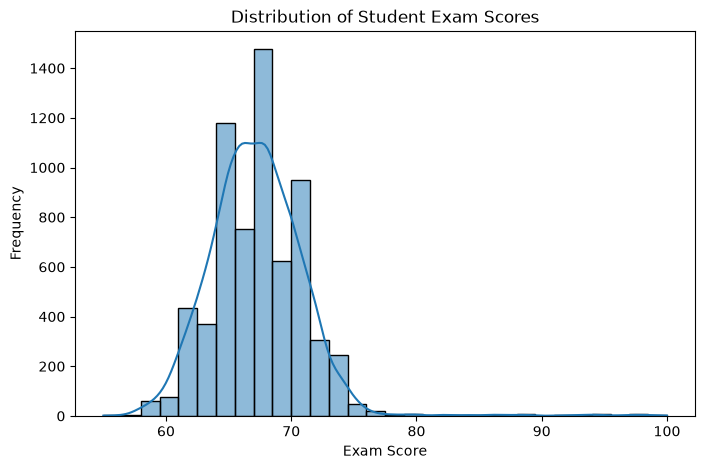

In [120]:
# Distribution of Exam Scores
plt.figure(figsize=(8, 5))

sns.histplot(df["Exam_Score"], bins=30, kde=True)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")

plt.show()

**Observation:** The distribution of exam scores is concentrated mainly in the mid-to-high 60s, with fewer students achieving scores above 80. A small number of students achieve exceptionally high scores, extending the distribution towards 100.

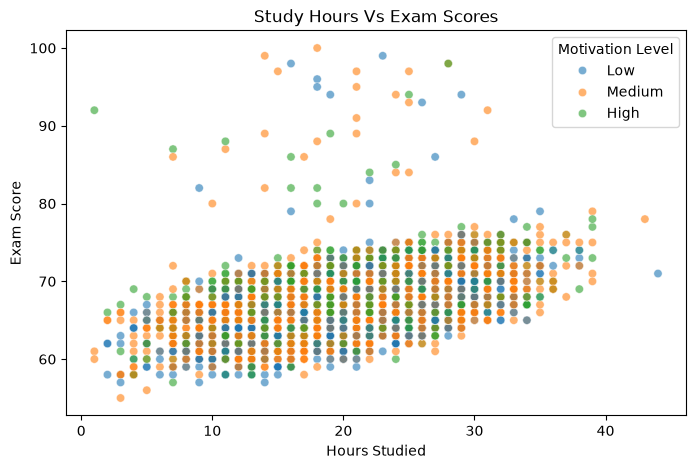

In [121]:
# Relationship between study hours and exam scores

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Hours_Studied", y="Exam_Score", hue="Motivation_Level", alpha=0.6)

plt.title("Study Hours Vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.legend(title="Motivation Level")

plt.show()

**Observation:** Exam scores generally show an upward trend as study hours increase. However, considerable variation exists among students with similar study hours. The different motivation levels overlap substantially, suggesting that study hours alone may not fully explain differences in academic performance.


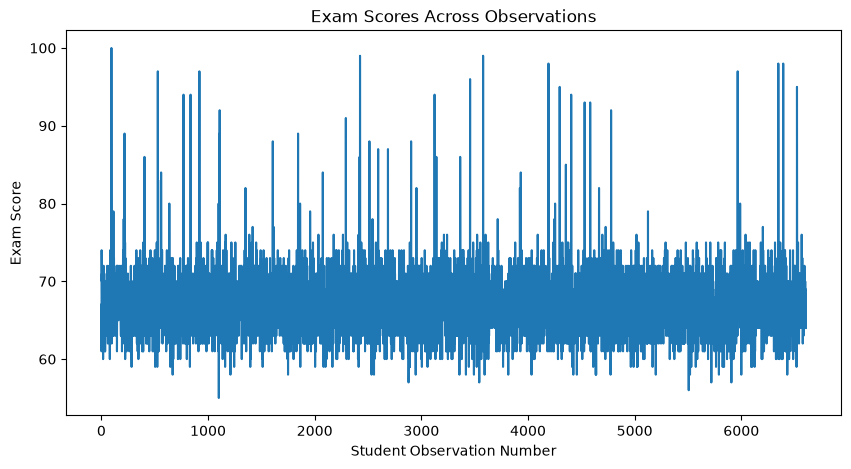

In [122]:
# Bike rental count across the dataset

plt.figure(figsize=(10, 5))
plt.plot(df["Exam_Score"])

plt.title("Exam Scores Across Observations")
plt.xlabel("Student Observation Number")
plt.ylabel("Exam Score")

plt.show()

**Observation:** Exam scores vary across the dataset, with most students scoring between approximately 60 and 75. A small number of students achieve scores above 80, with some reaching close to 100. The scores fluctuate across observations without a clear sequential trend.

In [123]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()


C:\Users\nayan\AppData\Local\Temp\ipykernel_21632\1992369538.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


In [124]:
# Define features (X) and target (y)

features = [
    "Hours_Studied",
    "Attendance",
    "Parental_Involvement",
    "Access_to_Resources",
    "Extracurricular_Activities",
    "Sleep_Hours",
    "Previous_Scores",
    "Motivation_Level",
    "Internet_Access",
    "Tutoring_Sessions",
    "Family_Income",
    "Teacher_Quality",
    "School_Type",
    "Peer_Influence",
    "Physical_Activity",
    "Learning_Disabilities",
    "Parental_Education_Level",
    "Distance_from_Home",
    "Gender"
]

X = df[features]
y = df["Exam_Score"]

print("Features:", X.columns.tolist())

Features: ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [125]:
# One-hot encode categorical variables

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    dtype=int
)

print("Features after encoding:")
print(X.columns.tolist())
print("\nNew X shape:", X.shape)

Features after encoding:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Parental_Involvement_High', 'Parental_Involvement_Low', 'Parental_Involvement_Medium', 'Access_to_Resources_High', 'Access_to_Resources_Low', 'Access_to_Resources_Medium', 'Extracurricular_Activities_No', 'Extracurricular_Activities_Yes', 'Motivation_Level_High', 'Motivation_Level_Low', 'Motivation_Level_Medium', 'Internet_Access_No', 'Internet_Access_Yes', 'Family_Income_High', 'Family_Income_Low', 'Family_Income_Medium', 'Teacher_Quality_High', 'Teacher_Quality_Low', 'Teacher_Quality_Medium', 'School_Type_Private', 'School_Type_Public', 'Peer_Influence_Negative', 'Peer_Influence_Neutral', 'Peer_Influence_Positive', 'Learning_Disabilities_No', 'Learning_Disabilities_Yes', 'Parental_Education_Level_College', 'Parental_Education_Level_High School', 'Parental_Education_Level_Postgraduate', 'Distance_from_Home_Far', 'Distance_from_Home_Moderate', 'Distance_

In [126]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5284, 40)
Testing features: (1322, 40)
Training target: (5284,)
Testing target: (1322,)


In [127]:
# Scale features for KNN

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (5284, 40)
Scaled testing data shape: (1322, 40)


## -> Core Machine Learning Models

### 1. Linear Regression

In [128]:
# Train a Linear Regression model

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [129]:
# Evaluate Linear Regression

# Evaluate Linear Regression model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred_linear)
mse = mean_squared_error(y_test, y_pred_linear)
rmse = np.sqrt(mse)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Model Evaluation:")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2_linear, 4))

Linear Regression Model Evaluation:
Mean Absolute Error (MAE): 0.42
Mean Squared Error (MSE): 2.31
Root Mean Squared Error (RMSE): 1.52
R2 Score: 0.825


Observation: Linear Regression achieved an MAE of 0.42, an MSE of 2.31, an RMSE of 1.52, and an R² score of 0.82. This indicates that the model explains approximately 82% of the variation in student exam scores, with relatively low prediction errors.

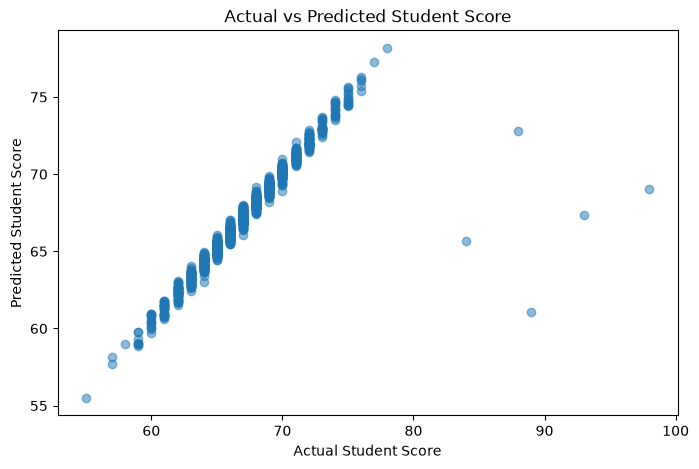

In [130]:
# Actual vs Predicted values

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_linear, alpha=0.5)

plt.title("Actual vs Predicted Student Score")
plt.xlabel("Actual Student Score")
plt.ylabel("Predicted Student Score")

plt.show()

**Observation:** The Actual vs Predicted graph shows that most predictions lie close to the ideal prediction line, indicating good model performance for the majority of students. However, a few observations with actual scores above 85 have considerably lower predicted scores. This suggests that the Linear Regression model struggles to predict some unusually high exam scores.

### 2. Decision Tree

In [131]:
# Train a Decision Tree Regressor

tree_model = DecisionTreeRegressor(random_state=42)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [132]:
# Evaluate Decision Tree

mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("Mean Absolute Error (MAE):", round(mae_tree, 2))
print("Mean Squared Error (MSE):", round(mse_tree, 2))
print("Root Mean Squared Error (RMSE):", round(np.sqrt(mse_tree), 2))
print("R2 Score:", round(r2_tree, 4))

Decision Tree Results
Mean Absolute Error (MAE): 1.87
Mean Squared Error (MSE): 14.32
Root Mean Squared Error (RMSE): 3.78
R2 Score: -0.0826


In [133]:

# Train a Decision Tree with limited depth (Took help from AI)

tree_model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

# Make predictions
y_pred_tree = tree_model.predict(X_test)

# Evaluate the model
mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)
r2_tree = r2_score(y_test, y_pred_tree)

print("Tuned Decision Tree Results")
print("MAE:", round(mae_tree, 2))
print("MSE:", round(mse_tree, 2))
print("RMSE:", round(np.sqrt(mse_tree), 2))
print("R²:", round(r2_tree, 2))


Tuned Decision Tree Results
MAE: 1.58
MSE: 5.7
RMSE: 2.39
R²: 0.57


**Observation:** The tuned Decision Tree Regression model achieved an MAE of 1.58, an RMSE of 2.39, and an R² score of 0.57. Limiting the tree's depth and increasing the minimum number of samples required for splits and leaf nodes improved its performance compared with the original Decision Tree. However, Linear Regression still provides more accurate predictions on the test set.

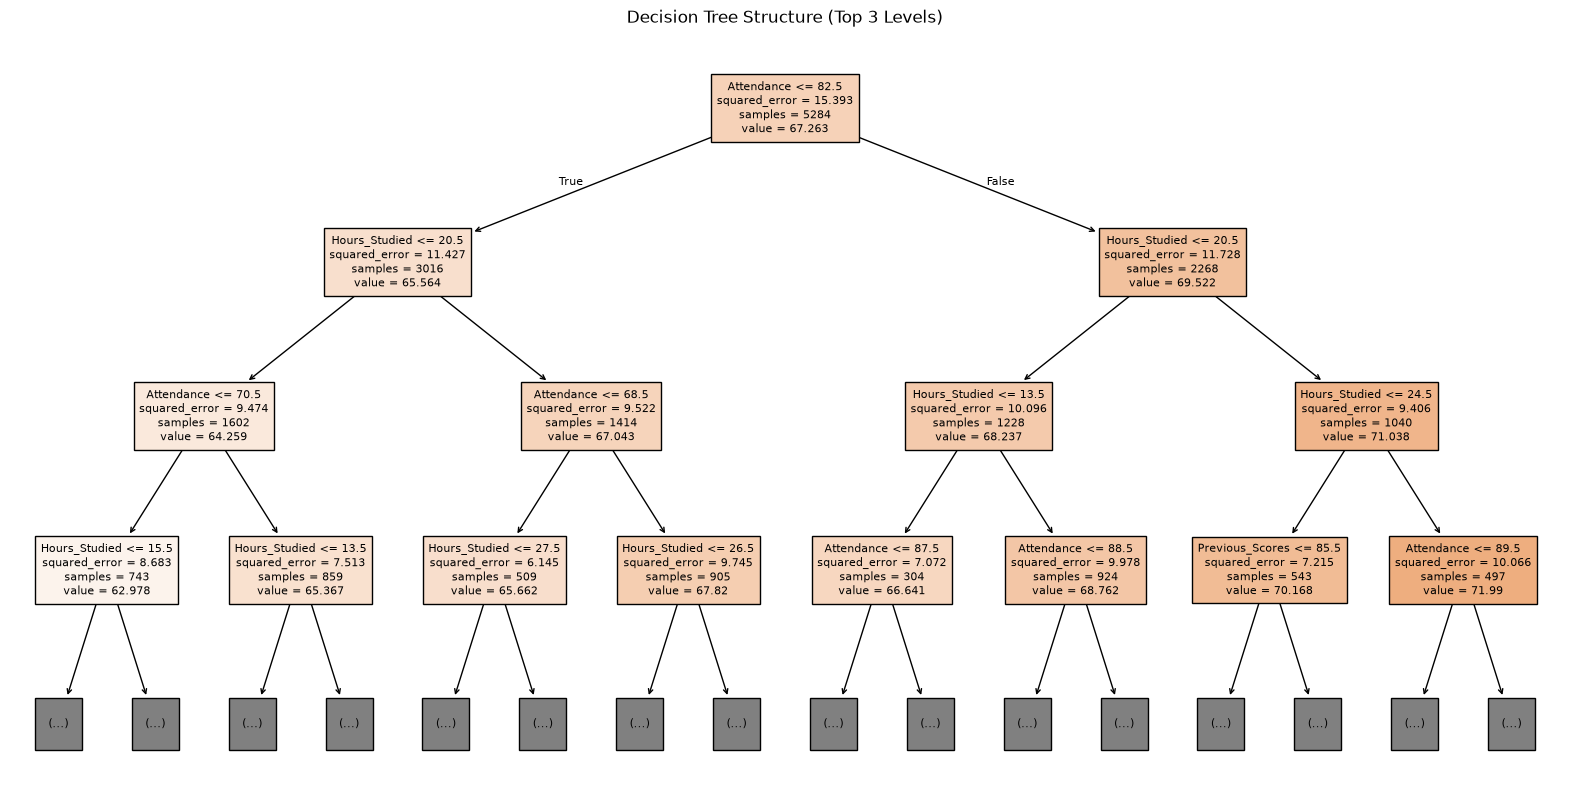

In [134]:
# Visualize the Decision Tree

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=X.columns,
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Structure (Top 3 Levels)")
plt.show()

**Observation:** The Decision Tree visualization shows that Attendance is the first feature used to split the data, followed by Hours_Studied and other features such as Previous_Scores. The tree divides students into smaller groups based on these conditions and predicts their exam scores using the average score of the samples in each leaf node. This helps illustrate how the model captures relationships between student-related factors and exam performance.

### 3. Random Forest Regressor

In [135]:
# Train a Random Forest Regressor

forest_model = RandomForestRegressor(
    random_state=42
)

forest_model.fit(X_train, y_train)

y_pred_forest = forest_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [136]:
# Evaluate Random Forest

mae_forest = mean_absolute_error(y_test, y_pred_forest)
mse_forest = mean_squared_error(y_test, y_pred_forest)
r2_forest = r2_score(y_test, y_pred_forest)

print("Random Forest Results")
print("MAE:", round(mae_forest, 2))
print("MSE:", round(mse_forest, 2))
print("RMSE:", round(np.sqrt(mse_forest), 2))
print("R²:", round(r2_forest, 2))

Random Forest Results
MAE: 1.07
MSE: 3.87
RMSE: 1.97
R²: 0.71


In [137]:
y_train_pred_forest = forest_model.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_forest))
print("Testing R²:", r2_score(y_test, y_pred_forest))

Training R²: 0.9486277463067667
Testing R²: 0.7075594330348591


In [138]:
feature_importance = pd.Series(
    forest_model.feature_importances_,
    index=X.columns
)

feature_importance = feature_importance.sort_values(ascending=False)

print("Top 3 Important Features:")
print(feature_importance.head(3))

Top 3 Important Features:
Attendance         0.377684
Hours_Studied      0.233188
Previous_Scores    0.085507
dtype: float64


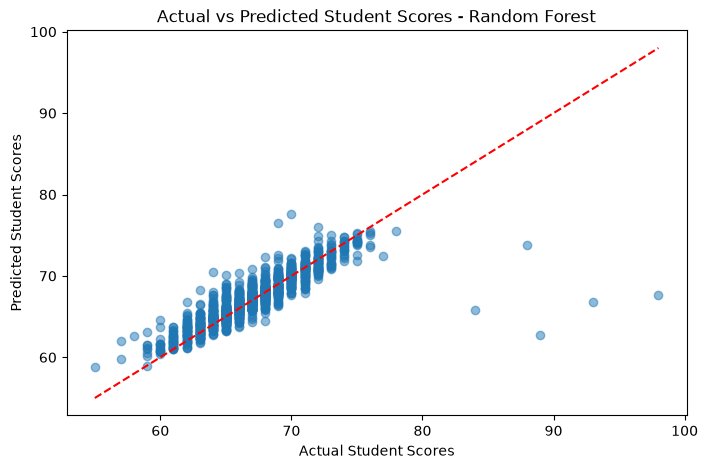

In [139]:

# Actual vs Predicted values for Random Forest

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_forest, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.title("Actual vs Predicted Student Scores - Random Forest")
plt.xlabel("Actual Student Scores")
plt.ylabel("Predicted Student Scores")

plt.show()


**Observation:** The Random Forest model shows a positive relationship between actual and predicted student scores. However, the predictions are concentrated around 60–75, and the model tends to underestimate students with very high scores. This indicates that the model captures general patterns but struggles to predict extreme scores accurately.

**Conclusion:** Random Forest achieved an R² score of approximately 0.71, indicating that it explains around 71% of the variation in student scores on the test set. Although it performs better than the Decision Tree, Linear Regression currently achieves better results on this test set. Further tuning and feature analysis may help improve performance.

### 4. K-Nearest Neighbour (KNN)

In [140]:
# Train KNN with K = 5

knn_model = KNeighborsRegressor(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN model trained successfully!")

KNN model trained successfully!


In [141]:
# Evaluate KNN with K = 5

mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)

print("KNN (K=5) Results")
print("MAE:", round(mae_knn, 2))
print("MSE:", round(mse_knn, 2))
print("RMSE:", round(np.sqrt(mse_knn), 2))
print("R²:", round(r2_knn, 2))

KNN (K=5) Results
MAE: 2.11
MSE: 8.6
RMSE: 2.93
R²: 0.35


In [142]:
# Train KNN with K = 3

knn_model_3 = KNeighborsRegressor(n_neighbors=3)

knn_model_3.fit(X_train_scaled, y_train)

y_pred_knn_3 = knn_model_3.predict(X_test_scaled)

# Evaluate KNN with K = 3

mae_knn_3 = mean_absolute_error(y_test, y_pred_knn_3)
mse_knn_3 = mean_squared_error(y_test, y_pred_knn_3)
r2_knn_3 = r2_score(y_test, y_pred_knn_3)

print("KNN (K=3) Results")
print("MAE:", round(mae_knn_3, 2))
print("MSE:", round(mse_knn_3, 2))
print("RMSE:", round(np.sqrt(mse_knn_3), 2))
print("R²:", round(r2_knn_3, 2))

KNN (K=3) Results
MAE: 2.19
MSE: 9.39
RMSE: 3.06
R²: 0.29


In [143]:
# Train KNN with K = 10

knn_model_10 = KNeighborsRegressor(n_neighbors=10)

knn_model_10.fit(X_train_scaled, y_train)

y_pred_knn_10 = knn_model_10.predict(X_test_scaled)

# Evaluate KNN with K = 10

mae_knn_10 = mean_absolute_error(y_test, y_pred_knn_10)
mse_knn_10 = mean_squared_error(y_test, y_pred_knn_10)
r2_knn_10 = r2_score(y_test, y_pred_knn_10)

print("KNN (K=10) Results")
print("MAE:", round(mae_knn_10, 2))
print("MSE:", round(mse_knn_10, 2))
print("RMSE:", round(np.sqrt(mse_knn_10), 2))
print("R²:", round(r2_knn_10, 2))

KNN (K=10) Results
MAE: 2.02
MSE: 7.94
RMSE: 2.82
R²: 0.4


Observation: Increasing K from 3 to 10 improved KNN's performance on the test set. K = 10 achieved the lowest MAE, MSE, and RMSE, along with the highest R² score of 0.40 among the three configurations tested.

Conclusion: K = 10 is the best-performing KNN configuration among those tested so far. However, it still performs worse than Linear Regression, which achieved an R² of 0.82.

In [144]:
# Compare all five models

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "KNN (K=10)"
    ],
    "Metric": [
        "R²",
        "R²",
        "R²",
        "R²"
    ],
    "Score": [
        r2_linear,
        r2_tree,
        r2_forest,
        r2_knn_10
    ]
})

comparison

,Model,Metric,Score
0,Linear Regression,R²,0.825000
1,Decision Tree,R²,0.568919
2,Random Forest,R²,0.707559
3,KNN (K=10),R²,0.399807


## Model Comparison and Final Choice

The four regression models were evaluated using the R² score, Mean Absolute Error (MAE), Mean Squared Error (MSE), and Root Mean Squared Error (RMSE).

Linear Regression achieved the best performance, with an R² score of approximately 0.825 and an MAE of 0.42. Random Forest ranked second with an R² score of approximately 0.708, followed by Decision Tree with 0.569 and KNN (K=10) with 0.400.

**Final Choice:** Linear Regression was selected as the best-performing model for predicting student performance based on the current test-set results. It achieved the highest R² score and the lowest MAE among the four models. However, the prediction plot indicates that the model may underestimate some unusually high student scores.


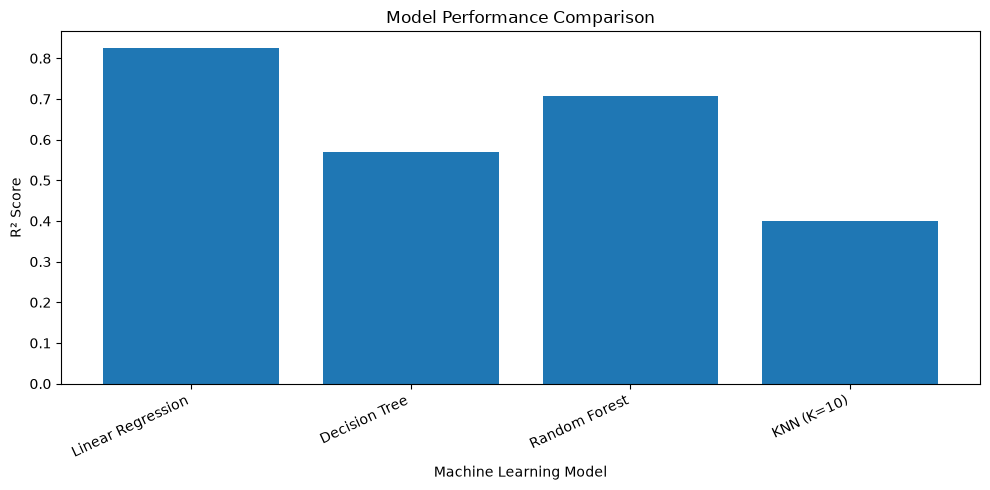

In [145]:

# Visualize model performance

plt.figure(figsize=(10, 5))

plt.bar(comparison["Model"], comparison["Score"])

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()
